In [ ]:
import ccxt
import pandas as pd
import numpy as np
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import requests
import schedule
import time
from IPython.display import display, clear_output
import threading

# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Customizable lookback periods
HISTORICAL_LOOKBACK = 100  # Number of 1-minute intervals to fetch historical data
VOLD_LOOKBACK = 50         # Number of 1-minute intervals for calculating VoLD ratio

# Fetch all USDT-paired spot symbols from Binance
def fetch_usdt_spot_symbols():
    usdt_symbols = [symbol for symbol in exchange.symbols if symbol.endswith('/USDT')]
    return usdt_symbols

# Function to fetch OHLCV data with a customizable lookback period
def fetch_ohlcv(symbol, timeframe='1m', limit=HISTORICAL_LOOKBACK):
    ohlcv = exchange.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
    return ohlcv

# Function to calculate the VoLD ratio
def calculate_vold_ratio(df):
    df['price_change'] = df['close'].diff()
    df['up_volume'] = np.where(df['price_change'] > 0, df['volume'], 0)
    df['down_volume'] = np.where(df['price_change'] < 0, df['volume'], 0)
    
    # Aggregate the volume of up and down candles over the VOLD_LOOKBACK period
    df['up_sum'] = df['up_volume'].rolling(window=VOLD_LOOKBACK, min_periods=1).sum()
    df['down_sum'] = df['down_volume'].rolling(window=VOLD_LOOKBACK, min_periods=1).sum()
    
    # Calculate VoLD ratio and ensure it's between -1 and 1
    df['vold_ratio'] = (df['up_sum'] - df['down_sum']) / (df['up_sum'] + df['down_sum'])
    df['vold_ratio'] = df['vold_ratio'].clip(-1, 1)  # Clipping the values to ensure they are within the range
    df['vold_ratio'] = df['vold_ratio'].fillna(0)  # Handle any NaN values
    
    return df

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Store historical data for calculation
historical_data = {}

def update_chart():
    # Fetch all USDT-paired spot symbols
    usdt_symbols = fetch_usdt_spot_symbols()

    # Initialize lists for aggregated volumes
    aggregated_up_volume = []
    aggregated_down_volume = []
    timestamps = []

    # Fetch OHLCV data and aggregate volumes for all symbols
    for symbol in usdt_symbols:
        ohlcv = fetch_ohlcv(symbol)
        df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')

        # Add new data to historical data
        if symbol not in historical_data:
            historical_data[symbol] = df
        else:
            historical_data[symbol] = pd.concat([historical_data[symbol], df]).drop_duplicates().tail(HISTORICAL_LOOKBACK)

        # Calculate the VoLD ratio for the current symbol
        df = calculate_vold_ratio(historical_data[symbol])
        
        # Aggregate up and down volumes
        aggregated_up_volume.extend(df['up_volume'].values)
        aggregated_down_volume.extend(df['down_volume'].values)
        timestamps = df['timestamp']  # Update timestamps to the latest one

    # Calculate the total VoLD ratio for each minute
    vold_ratios = []
    for i in range(VOLD_LOOKBACK, len(timestamps)):  # Start at VOLD_LOOKBACK to ensure enough data
        total_up_sum = np.sum(aggregated_up_volume[i-VOLD_LOOKBACK:i])
        total_down_sum = np.sum(aggregated_down_volume[i-VOLD_LOOKBACK:i])
        
        if total_up_sum + total_down_sum > 0:
            vold_ratio = (total_up_sum - total_down_sum) / (total_up_sum + total_down_sum)
        else:
            vold_ratio = 0
        
        vold_ratios.append(np.clip(vold_ratio, -1, 1))  # Clipping to -1 and 1
    
    # Create a DataFrame for plotting
    vold_df = pd.DataFrame({
        'timestamp': timestamps[VOLD_LOOKBACK:],  # Skip the first VOLD_LOOKBACK bars
        'vold_ratio': vold_ratios
    })

    # Clear the existing figure
    fig.data = []

    # Add bar trace for VoLD ratio
    bars = go.Bar(
        x=vold_df['timestamp'],
        y=vold_df['vold_ratio'],
        marker_color=np.where(vold_df['vold_ratio'] > 0, 'blue', 'red')
    )

    fig.add_trace(bars, row=1, col=1)

    # Add horizontal line at y=0 for reference
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

     # Add horizontal lines at specified levels
    for level in [-0.8,-0.6,-0.4,-0.2,0, 0.2, 0.4, 0.6, 0.8, 1]:
        fig.add_hline(y=level, line=dict(color='white', width=1, dash='dot'), row=1, col=1)


    # Update layout for better visualization
    fig.update_layout(
        title=f'Crypto VoLD Ratio Histogram',
        xaxis_title='Time',
        yaxis_title='VoLD Ratio',
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray'),
        yaxis=dict(
            showgrid=True,
            gridcolor='gray'
        )
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  #Run for 3 hours
stop_scheduler()
scheduler_thread.join()

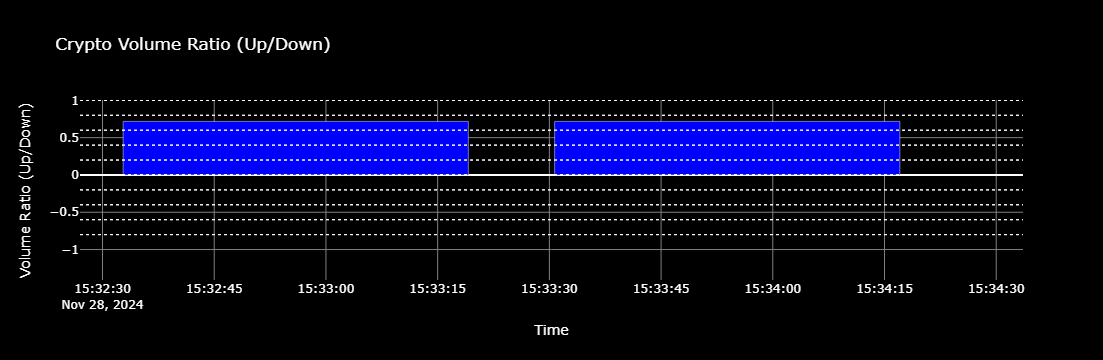

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objs as go
from plotly.subplots import make_subplots  # Make sure this import is included
import schedule
import time
from IPython.display import display, clear_output
import threading
import ccxt
exchange = ccxt.binance()

# Create a DataFrame to store the volume ratios
volume_ratios = []
timestamps = []

# Initialize the exchange
exchange = ccxt.binance()

# Function to fetch and calculate the volume ratio
def calculate_volume_ratio():
    # Fetch all USDT-paired symbols
    tickers = exchange.fetch_tickers()
    usdt_pairs = [symbol for symbol in tickers if symbol.endswith('/USDT')]

    # Initialize variables
    up_volume = 0  # Sum of volumes for advancing cryptos
    down_volume = 0  # Sum of volumes for declining cryptos

    # Loop through each symbol to classify and sum volumes
    for symbol in usdt_pairs:
        try:
            # Fetch ticker data
            ticker = exchange.fetch_ticker(symbol)
            percentage_change = ticker.get('percentage', None)
            volume = ticker.get('quoteVolume', None)  # Use quoteVolume for 24-hour volume
            
            # Skip invalid or missing data
            if percentage_change is None or volume is None:
                continue

            # Classify and sum volumes
            if percentage_change > 0:  # Advancing crypto
                up_volume += volume
            elif percentage_change < 0:  # Declining crypto
                down_volume += volume
        except Exception as e:
            print(f"Error fetching data for {symbol}: {e}")
            continue

    # Calculate the volume ratio (handle division by zero)
    volume_ratio = up_volume / down_volume if down_volume > 0 else None

    # Store the ratio and timestamp
    timestamp = pd.Timestamp.now()
    volume_ratios.append(volume_ratio)
    timestamps.append(timestamp)

    # Display the volume ratio
    if volume_ratio is not None:
        print(f"Volume Ratio (Up/Down): {volume_ratio:.2f}")
    else:
        print("Volume Ratio (Up/Down): Undefined (No declining cryptos)")

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Function to update the chart
def update_chart():
    # Fetch and calculate the volume ratio
    calculate_volume_ratio()

    # Create a DataFrame for plotting
    vold_df = pd.DataFrame({
        'timestamp': timestamps[-200:],  # Keep the last 200 entries for the plot
        'vold_ratio': volume_ratios[-200:]
    })

    # Clear the existing figure
    fig.data = []

    # Add bar trace for Volume Ratio
    bars = go.Bar(
        x=vold_df['timestamp'],
        y=vold_df['vold_ratio'],
        marker_color=np.where(vold_df['vold_ratio'] > 0, 'blue', 'red')
    )

    fig.add_trace(bars, row=1, col=1)

    # Add horizontal line at y=0 for reference
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Add horizontal lines at specified levels
    for level in [-0.8,-0.6,-0.4,-0.2,0, 0.2, 0.4, 0.6, 0.8, 1]:
        fig.add_hline(y=level, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title='Crypto Volume Ratio (Up/Down)',
        xaxis_title='Time',
        yaxis_title='Volume Ratio (Up/Down)',
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray'),
        yaxis=dict(
            showgrid=True,
            gridcolor='gray'
        )
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()


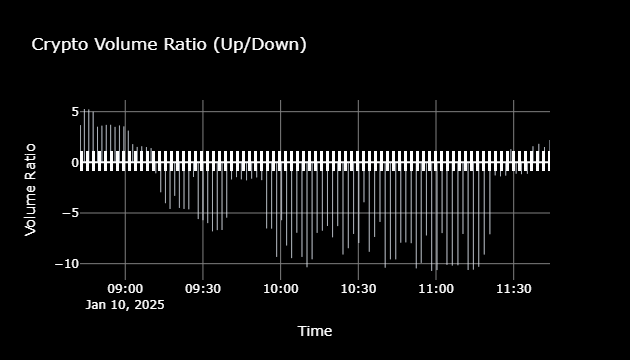

In [3]:
import numpy as np
import pandas as pd
import plotly.graph_objs as go
from plotly.subplots import make_subplots  # Ensure this import is included
import schedule
import time
from IPython.display import display, clear_output
import threading
import ccxt

# Initialize the exchange
exchange = ccxt.binance()

# Create a DataFrame to store the volume ratios
volume_ratios = []
timestamps = []

# Function to fetch and calculate the volume ratio
def calculate_volume_ratio():
    # Fetch all USDT-paired symbols
    tickers = exchange.fetch_tickers()
    usdt_pairs = [symbol for symbol in tickers if symbol.endswith('/USDT')]

    # Initialize variables
    up_volume = 0  # Sum of volumes for advancing cryptos
    down_volume = 0  # Sum of volumes for declining cryptos

    # Loop through each symbol to classify and sum volumes
    for symbol in usdt_pairs:
        try:
            # Fetch ticker data
            ticker = exchange.fetch_ticker(symbol)
            percentage_change = ticker.get('percentage', None)
            volume = ticker.get('quoteVolume', None)  # Use quoteVolume for 24-hour volume

            # Skip invalid or missing data
            if percentage_change is None or volume is None:
                continue

            # Classify and sum volumes
            if percentage_change > 0:  # Advancing crypto
                up_volume += volume
            elif percentage_change < 0:  # Declining crypto
                down_volume += volume
        except Exception as e:
            print(f"Error fetching data for {symbol}: {e}")
            continue

    # Calculate the volume ratio
    if down_volume > up_volume and up_volume > 0:
        volume_ratio = -down_volume / up_volume  # Use a negative value for clarity
    elif down_volume > 0:
        volume_ratio = up_volume / down_volume
    else:
        volume_ratio = None  # Undefined when no volumes are present

    # Store the ratio and timestamp
    timestamp = pd.Timestamp.now()
    volume_ratios.append(volume_ratio)
    timestamps.append(timestamp)

    # Display the volume ratio
    if volume_ratio is not None:
        print(f"Volume Ratio: {volume_ratio:.2f}")
    else:
        print("Volume Ratio: Undefined (No advancing or declining cryptos)")

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Function to update the chart
def update_chart():
    # Fetch and calculate the volume ratio
    calculate_volume_ratio()

    # Create a DataFrame for plotting
    vold_df = pd.DataFrame({
        'timestamp': timestamps[-200:],  # Keep the last 200 entries for the plot
        'vold_ratio': volume_ratios[-200:]
    })

    # Clear the existing figure
    fig.data = []

    # Add bar trace for Volume Ratio
    bars = go.Bar(
        x=vold_df['timestamp'],
        y=vold_df['vold_ratio'],
        marker_color=np.where(vold_df['vold_ratio'] > 0, 'blue', 'red')
    )

    fig.add_trace(bars, row=1, col=1)

    # Add horizontal line at y=0 for reference
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Add horizontal lines at specified levels
    for level in [-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 1]:
        fig.add_hline(y=level, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title='Crypto Volume Ratio (Up/Down)',
        xaxis_title='Time',
        yaxis_title='Volume Ratio',
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray'),
        yaxis=dict(
            showgrid=True,
            gridcolor='gray'
        )
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output
import threading
import ccxt
import logging

# Initialize the exchange
exchange = ccxt.binance()

# Set up logging
logging.basicConfig(level=logging.INFO)

# Create a DataFrame to store the volume ratios
volume_ratios = []
timestamps = []

# Retry settings
max_retries = 5
backoff_factor = 2  # Exponential backoff

# Function to fetch and calculate the volume ratio
def calculate_volume_ratio():
    # Fetch all USDT-paired symbols
    tickers = exchange.fetch_tickers()
    usdt_pairs = [symbol for symbol in tickers if symbol.endswith('/USDT')]

    # Initialize variables
    up_volume = 0  # Sum of volumes for advancing cryptos
    down_volume = 0  # Sum of volumes for declining cryptos

    # Loop through each symbol to classify and sum volumes
    for symbol in usdt_pairs:
        retries = 0
        while retries < max_retries:
            try:
                # Fetch ticker data
                ticker = exchange.fetch_ticker(symbol)
                percentage_change = ticker.get('percentage', None)
                volume = ticker.get('quoteVolume', None)  # Use quoteVolume for 24-hour volume

                # Skip invalid or missing data
                if percentage_change is None or volume is None:
                    continue

                # Classify and sum volumes
                if percentage_change > 0:  # Advancing crypto
                    up_volume += volume
                elif percentage_change < 0:  # Declining crypto
                    down_volume += volume

                break  # Successfully fetched data, break out of retry loop
            except ccxt.NetworkError as e:
                logging.warning(f"Network error for {symbol}: {e}. Retrying...")
                time.sleep(5)  # Delay before retrying
                retries += 1
            except ccxt.ExchangeError as e:
                logging.warning(f"Exchange error for {symbol}: {e}. Retrying...")
                time.sleep(5)  # Delay before retrying
                retries += 1
            except ccxt.BaseError as e:
                # Handle rate limit or other ccxt errors
                if 'APIError(code=-1003)' in str(e):
                    logging.warning(f"Rate limit exceeded for {symbol}. Retrying after backoff...")
                    time.sleep(60)  # If rate-limited, wait for 60 seconds
                    retries += 1
                else:
                    logging.error(f"Error fetching data for {symbol}: {e}. Retrying with backoff...")
                    time.sleep(backoff_factor ** retries)  # Exponential backoff on other errors
                    retries += 1

        if retries == max_retries:
            logging.error(f"Failed to fetch data for {symbol} after {max_retries} retries.")
            continue  # Skip to the next symbol if max retries reached

    # Calculate the volume ratio
    if down_volume > up_volume and up_volume > 0:
        volume_ratio = -down_volume / up_volume  # Use a negative value for clarity
    elif down_volume > 0:
        volume_ratio = up_volume / down_volume
    else:
        volume_ratio = None  # Undefined when no volumes are present

    # Store the ratio and timestamp
    timestamp = pd.Timestamp.now()
    volume_ratios.append(volume_ratio)
    timestamps.append(timestamp)

    # Display the volume ratio
    if volume_ratio is not None:
        print(f"Volume Ratio: {volume_ratio:.2f}")
    else:
        print("Volume Ratio: Undefined (No advancing or declining cryptos)")

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Function to update the chart
def update_chart():
    # Fetch and calculate the volume ratio
    calculate_volume_ratio()

    # Create a DataFrame for plotting
    vold_df = pd.DataFrame({
        'timestamp': timestamps[-200:],  # Keep the last 200 entries for the plot
        'vold_ratio': volume_ratios[-200:]
    })

    # Clear the existing figure
    fig.data = []

    # Add bar trace for Volume Ratio
    bars = go.Bar(
        x=vold_df['timestamp'],
        y=vold_df['vold_ratio'],
        marker_color=np.where(vold_df['vold_ratio'] > 0, 'blue', 'red')
    )

    fig.add_trace(bars, row=1, col=1)

    # Add horizontal line at y=0 for reference
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Add horizontal lines at specified levels
    for level in [-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 1]:
        fig.add_hline(y=level, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title='Crypto Volume Ratio (Up/Down)',
        xaxis_title='Time',
        yaxis_title='Volume Ratio',
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray'),
        yaxis=dict(
            showgrid=True,
            gridcolor='gray'
        )
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()